# Tweet Analysis

Nom et prénom des membres du groupe :

* MOUSSA NIZAR Akidat
* NASSERA NABGAOUI
* EL AIDOUNI Chirine
* MAURIN Paul


##Introduction
Dans ce projet, nous cherchons à classifier automatiquement des tweets selon leur relation à la science. Plus précisément, trois tâches sont étudiées :


*   Tâche 1: distinguer les tweets scientifiques des non scientifiques

*   Tâche 2: distinguer les tweets contenant une revendication ou une référence scientifique de ceux donnant uniquement du contexte
*   Tâche 3: classifier les tweets scientifiques en trois catégories : claim, reference ou context

Pour ce faire, nous adoptons une démarche complète, couvrant l’ensemble du processus depuis l’analyse exploratoire des données jusqu’à l’optimisation des modèles de machine learning.



## Imports

In [ ]:
!pip install emoji

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
import re
import sqlite3
import warnings
from typing import Callable, Any
import sys
warnings.filterwarnings('ignore')

from collections import Counter
from google.colab import drive
import json

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

import emoji

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.base import clone
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import MultiLabelBinarizer


from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import MaxAbsScaler

import unicodedata


from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

print('Imports OK')

Imports OK


## Configuration
Chaque utilisateur doit définir le chemin d’accès correspondant à son espace Google Drive personnel.

In [ ]:
!ls -la "/content/drive/Shareddrives"

ls: cannot access '/content/drive/Shareddrives': No such file or directory


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
my_local_drive='/content/drive/MyDrive/Projet ML1 Master ICo'
sys.path.append(my_local_drive)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Raw Data
Chargement des données brutes

In [ ]:
df = pd.read_csv(my_local_drive+'/scitweets_export.csv', na_values='na', sep="\t", index_col=0).reset_index(drop=True)
df_original = df.copy()

In [ ]:
import os

print(f"Contents of my_local_drive ({my_local_drive}):")
if os.path.exists(my_local_drive):
    print(os.listdir(my_local_drive))
else:
    print(f"The directory '{my_local_drive}' does not exist.")

a_trier_path = '/content/drive/MyDrive/a trier/'
print(f"\nContents of '{a_trier_path}':")
if os.path.exists(a_trier_path):
    print(os.listdir(a_trier_path))
else:
    print(f"The directory '{a_trier_path}' does not exist.")


Contents of my_local_drive (/content/drive/MyDrive/Projet ML1 Master ICo):
['SciTweetsData.pdf', '3511808.3557693.pdf', 'Projet 2026 - Machine Learning I - HAI817-2.pdf', 'scitweets_export.csv', 'Document ML.gdoc', 'figures', 'resultats_ml.json', 'Scitweets_OvR.pdf', 'Scitweets_OvR.ipynb', 'Scitweets.ipynb', 'Scitweets.pdf']

Contents of '/content/drive/MyDrive/a trier/':
The directory '/content/drive/MyDrive/a trier/' does not exist.


In [ ]:
df.head(10)

,tweet_id,text,science_related,scientific_claim,scientific_reference,scientific_context
0,316669998137483264,Knees are a bit sore. i guess that's a sign th...,0,0.0,0.0,0.0
1,319090866545385472,McDonald's breakfast stop then the gym 🏀💪,0,0.0,0.0,0.0
2,322030931022065664,Can any Gynecologist with Cancer Experience ex...,1,1.0,0.0,0.0
3,322694830620807168,Couch-lock highs lead to sleeping in the couch...,1,1.0,0.0,0.0
4,328524426658328576,Does daily routine help prevent problems with ...,1,1.0,0.0,0.0
5,331396203700944896,The Impact of Infertility on You and Your Rela...,0,0.0,0.0,0.0
6,333266791960809472,“Traffic Jam” In Brain’s Neurons Could Be Caus...,1,1.0,1.0,1.0
7,334282732085587968,Can playing more games improve lives and save ...,1,1.0,0.0,0.0
8,334350038090276864,The effect of climate change on iceberg produc...,1,0.0,1.0,1.0
9,335542235452014594,@HankAzaria @TheSimpsons oh loneliness and che...,0,0.0,0.0,0.0


In [ ]:
df.dtypes

,0
tweet_id,int64
text,object
science_related,int64
scientific_claim,float64
scientific_reference,float64
scientific_context,float64


In [ ]:
df.shape

(1140, 6)

In [ ]:
df.describe()

,tweet_id,science_related,scientific_claim,scientific_reference,scientific_context
count,1.140000e+03,1140.000000,1140.000000,1140.00000,1140.000000
mean,8.560901e+17,0.328947,0.230702,0.17807,0.220175
std,2.865422e+17,0.470037,0.421467,0.38274,0.414547
min,3.166700e+17,0.000000,0.000000,0.00000,0.000000
25%,6.176042e+17,0.000000,0.000000,0.00000,0.000000
50%,8.615253e+17,0.000000,0.000000,0.00000,0.000000
75%,1.103864e+18,1.000000,0.000000,0.00000,0.000000
max,1.344485e+18,1.000000,1.000000,1.00000,1.000000


# 1. Analyse des données

##1.1 Répartition des classes.
Le jeu de données contient 1140 tweets.


Nous observons qu'environ 33% des tweets sont science_related tandis que 67% ne le sont pas. Ainsi, un modèle prédisant systématiquement la classe majoritaire (non-science_related) atteindrait une précision d’environ 67 %, sans réelle capacité à différencier les classes. Cela met en évidence un problème de déséquilibre des classes (imbalanced dataset).
Nous analysons à présent la répartition des sous-classes au sein des tweets identifiés comme scientifiques.

In [ ]:
df.query("science_related == 1").describe()




,tweet_id,science_related,scientific_claim,scientific_reference,scientific_context
count,3.750000e+02,375.0,375.000000,375.000000,375.000000
mean,8.602661e+17,1.0,0.701333,0.541333,0.669333
std,2.899685e+17,0.0,0.458285,0.498954,0.471082
min,3.220309e+17,1.0,0.000000,0.000000,0.000000
25%,6.301684e+17,1.0,0.000000,0.000000,0.000000
50%,8.500253e+17,1.0,1.000000,1.000000,1.000000
75%,1.116759e+18,1.0,1.000000,1.000000,1.000000
max,1.340456e+18,1.0,1.000000,1.000000,1.000000


In [ ]:
df.query("science_related == 1 & scientific_claim == 0 & scientific_reference == 0 & scientific_context == 0").describe()


,tweet_id,science_related,scientific_claim,scientific_reference,scientific_context
count,0.0,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN


In [ ]:
df.query("science_related == 0 & (scientific_claim == 1 | scientific_reference == 1 | scientific_context == 1)").describe()


,tweet_id,science_related,scientific_claim,scientific_reference,scientific_context
count,0.0,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN


## 1.2. Sanity check

Dès le départ, un contrôle de cohérence est réalisé afin de vérifier la validité des hypothèses du jeu de données. Nous vérifions notamment que science_related = 1, au moins l’une des variables suivantes est égale à 1 : :

*   scientific_reference
*   scientific_claim
*   scientific_context

Cette propriété est vérifiée sur l’ensemble des données. Par ailleurs, l’absence de doublons dans les identifiants des tweets est confirmée ce qui garantit la qualité des données.

In [ ]:
print("nombre de doublons : ", df.duplicated("tweet_id").sum())

nombre de doublons :  0


##1.3 Analyse de la différence de longueur de tweets
Une analyse a été menée sur la longueur des tweets. Il semble que la longueur des tweets soit représentative de la classe.
La longueur en nb_char est plus représentative (14.0% plus élevée en moyenne pour 1 p/r à 0) que la longueur en nb_mots (5.7%), la longueur moyenne des mots est 10% plus élevée chez les science_related.

In [ ]:

def count_words (text:str)-> int :
    return len(text.split())

def count_chars (text:str)-> int :
  return len(text)

def long_moy_mots (text:str)-> float :
  return len(text)/len(text.split())

df['nb_words'] = df['text'].apply(count_words)
df['nb_chars'] = df['text'].apply(count_chars)
df['mean_len_words'] = df['text'].apply(long_moy_mots)

df[['text','nb_words', 'nb_chars','mean_len_words']].head(20)


,text,nb_words,nb_chars,mean_len_words
0,Knees are a bit sore. i guess that's a sign th...,16,82,5.125000
1,McDonald's breakfast stop then the gym 🏀💪,7,41,5.857143
2,Can any Gynecologist with Cancer Experience ex...,21,139,6.619048
3,Couch-lock highs lead to sleeping in the couch...,13,75,5.769231
4,Does daily routine help prevent problems with ...,10,85,8.500000
5,The Impact of Infertility on You and Your Rela...,10,77,7.700000
6,“Traffic Jam” In Brain’s Neurons Could Be Caus...,13,106,8.153846
7,Can playing more games improve lives and save ...,16,118,7.375000
8,The effect of climate change on iceberg produc...,12,95,7.916667
9,@HankAzaria @TheSimpsons oh loneliness and che...,10,76,7.600000


In [ ]:
print('Moyenne et Écart-type du nb_mots groupby', df.groupby(["science_related"])["nb_words"].agg(['mean','std']))

print('\nMoyenne et Écart-type du nb_chars groupby',df.groupby(["science_related"])["nb_chars"].agg(['mean','std']))

print('\nMoyenne et Écart-type du long_moy_mots groupby',df.groupby(["science_related"])['mean_len_words'].agg(['mean','std']))


Moyenne et Écart-type du nb_mots groupby                       mean        std
science_related                      
0                18.870588  10.001321
1                19.952000  11.099590

Moyenne et Écart-type du nb_chars groupby                        mean        std
science_related                       
0                130.969935  64.637089
1                149.336000  78.240266

Moyenne et Écart-type du long_moy_mots groupby                      mean       std
science_related                    
0                7.172719  1.550427
1                7.809144  1.576751


#2. Pré-traitement des données
Le texte brut doit être transformé afin de pouvoir être exploité par les modèles de machine learning.
Nous appliquons un pipeline de nettoyage en plusieurs étapes.
## 2.1 Parsing et nettoyage du texte

Séquentiellement

1. Identifier les emojis: compter puis supprimer
2. Identifier les hashtags: compter puis supprimer
3. Identifier les @: compter puis supprimer
4. Identifier les liens: compter et supprimer
5. Remove stop words (vérifier si langue anglaise)
6. Remove non ascii caractères
7. Identifier s'il y a un chiffre ou un nombre hors id dans les #
8. identifier s'il y a des poncutations spécifiques comme ?  

##2.1. Emojis

###2.1.1. Identification des emojis

In [ ]:


def count_emojis(text: str) -> int:
  return sum(1 for ch in text if ch in emoji.EMOJI_DATA)

def remove_emoji(text: str) -> str:
    return "".join(ch for ch in text if ch not in emoji.EMOJI_DATA)

def treat_emoji(df):
    df['nb_emoji'] = df['text'].apply(count_emojis)
    df['text_cleaned']=df['text_cleaned'].apply(remove_emoji)
    return df


df['nb_emoji'] = df['text'].apply(count_emojis)


###2.1.2 Elimination des émojis du text_clean
Nous retirons simplement tous les émojis

In [ ]:
df['text_cleaned']=df['text'].apply(remove_emoji)

print("Emojis restantes :" , df['text_cleaned'].apply(count_emojis).sum())

Emojis restantes : 0


##2.2. Hastags
Les symboles # sont identifiés dans le texte. Les hashtags sont des éléments fréquents dans les tweets et peuvent contenir des informations utiles.
Dans notre approche, nous choisissons de conserver le contenu du hashtag tout en supprimant uniquement le symbole "#". Cela permet de garder les mots associés tout en standardisant le texte.



###2.2.1. Identification des \#

In [ ]:
## Identifier les #: compter puis supprimer

def count_hastag(text: str) -> int:
  return sum(1 for ch in text if ch =='#')

## ici il faut se demander si on retire tout le contenu du hashtag ou simplement le symbole

def remove_hashtag(text: str) -> str:
    return "".join(ch for ch in text if ch !='#')

def treat_hashtag(df):
  df['nb_hashtag'] = df['text'].apply(count_hastag)
  df['text_cleaned']=df['text_cleaned'].apply(remove_hashtag)
  return df

#df[['text','nb_words', 'nb_chars','mean_len_words','nb_hashtag', 'science_related']].head(20)

###2.2.2 Elimination des \# du text_clean
Finalement, seul le symbole # est supprimé, tandis que le contenu du hashtag est conservé afin de préserver le sens du tweet.

In [ ]:
print("Hastag restants :" , df['text_cleaned'].apply(count_hastag).sum())

Hastag restants : 734


##2.3. Traitement des @
Les symboles @ sont identifiés dans le texte. Les mentions @ sont supprimées intégralement car elles n’apportent
pas d’information pertinente pour la tâche de classification. Ce choix permet de réduire le bruit dans les données.



###2.3.1 Identification des @

In [ ]:
## Identifier les @: compter puis supprimer

def count_arobases(text: str) -> int:
  return len(re.findall(r"@[^\s]+", text))


## ici on retire tout le contenu du arobase

def remove_arobases(text: str) -> str:
  # Supprimer @ + tous les caractères non-espace qui suivent
  cleaned = re.sub(r'@[^\s]+', '', text)
  # Optionnel : nettoyer les espaces multiples
  cleaned = re.sub(r'\s{2,}', ' ', cleaned).strip()
  return cleaned

def treat_arobase(df):
  df['nb_arobases'] = df['text'].apply(count_arobases)
  df['text_cleaned']=df['text_cleaned'].apply(remove_arobases)
  return df

#df[['text','text_cleaned', 'nb_words', 'nb_chars','mean_len_words', 'nb_arobases']].head(20)

###2.3.2. Elimination des @ du text_clean

La variabilité des @ref est très grande, nous retrouvons peu de @ref redondants.
Nous retirons donc les @ref en entier contrairement aux #ref.

In [ ]:
#df['text_cleaned']=df['text_cleaned'].apply(remove_arobases)
print("@ restantes :" , df['text_cleaned'].apply(count_arobases).sum())


@ restantes : 762


In [ ]:
#df["is_arobase"]  = df.apply(lambda row: 1 if "@" in row["text_cleaned"] else 0, axis=1)
#df.query("is_arobase == 1")[["text","nb_arobases"]]

##2.4. Traitement des liens
Les liens sont détectés à l’aide d’expressions régulières puis supprimés.
Bien qu’un lien puisse indiquer un contenu informatif, sa forme brute n’est pas directement exploitable par les modèles.


###2.4.1 Identification des liens

In [ ]:

def count_links(text: str) -> int:
  return len(re.findall(r'(https?://)?[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}(/[^\s]*)?', text))


def remove_links(text: str) -> int:
  return re.sub(r'(https?://)?[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}(/[^\s]*)?',"", text)

def treat_links(df):
  df['nb_links'] = df['text'].apply(count_links)
  df['text_cleaned']=df['text_cleaned'].apply(remove_links)
  return df

print(df.query("tweet_id==710072387220475904")['text'].apply(remove_links))



396    CGA for the non-specialist  from @JohnGladman1...
Name: text, dtype: object


##2.5. Retrait des non-ASCII
Les caractères non-ASCII sont supprimés.
Cette étape permet d’éliminer les symboles ou écritures non pertinentes pour l’analyse linguistique.

In [ ]:
def remove_non_ASCII(text: str) -> str:
  return re.sub(r'[^\w\s]', '', text)

def treat_non_ascii(df):
  df["text_cleaned"] = df.apply(lambda row: remove_non_ASCII(row['text_cleaned']), axis=1)
  return df

treat_non_ascii(df)

,tweet_id,text,science_related,scientific_claim,scientific_reference,scientific_context,nb_words,nb_chars,mean_len_words,nb_emoji,text_cleaned
0,316669998137483264,Knees are a bit sore. i guess that's a sign th...,0,0.0,0.0,0.0,16,82,5.125000,0,Knees are a bit sore i guess thats a sign that...
1,319090866545385472,McDonald's breakfast stop then the gym 🏀💪,0,0.0,0.0,0.0,7,41,5.857143,2,McDonalds breakfast stop then the gym
2,322030931022065664,Can any Gynecologist with Cancer Experience ex...,1,1.0,0.0,0.0,21,139,6.619048,0,Can any Gynecologist with Cancer Experience ex...
3,322694830620807168,Couch-lock highs lead to sleeping in the couch...,1,1.0,0.0,0.0,13,75,5.769231,0,Couchlock highs lead to sleeping in the couch ...
4,328524426658328576,Does daily routine help prevent problems with ...,1,1.0,0.0,0.0,10,85,8.500000,0,Does daily routine help prevent problems with ...
...,...,...,...,...,...,...,...,...,...,...,...
1135,1340455669443350528,@LaylaFanucci @realDonaldTrump I'm sorry but w...,1,1.0,0.0,0.0,43,242,5.627907,0,LaylaFanucci realDonaldTrump Im sorry but we D...
1136,1340689510569549824,"Dear #NIN applicants, you can kindly download ...",0,0.0,0.0,0.0,39,274,7.025641,1,Dear NIN applicants you can kindly download th...
1137,1341155832793165825,Whats the uber support team email address?,0,0.0,0.0,0.0,7,42,6.000000,0,Whats the uber support team email address
1138,1344167355648241664,House passes bill to increase stimulus checks ...,0,0.0,0.0,0.0,10,79,7.900000,0,House passes bill to increase stimulus checks ...


In [ ]:
df[['text','text_cleaned']].head(30)

,text,text_cleaned
0,Knees are a bit sore. i guess that's a sign th...,Knees are a bit sore i guess thats a sign that...
1,McDonald's breakfast stop then the gym 🏀💪,McDonalds breakfast stop then the gym
2,Can any Gynecologist with Cancer Experience ex...,Can any Gynecologist with Cancer Experience ex...
3,Couch-lock highs lead to sleeping in the couch...,Couchlock highs lead to sleeping in the couch ...
4,Does daily routine help prevent problems with ...,Does daily routine help prevent problems with ...
5,The Impact of Infertility on You and Your Rela...,The Impact of Infertility on You and Your Rela...
6,“Traffic Jam” In Brain’s Neurons Could Be Caus...,Traffic Jam In Brains Neurons Could Be Cause O...
7,Can playing more games improve lives and save ...,Can playing more games improve lives and save ...
8,The effect of climate change on iceberg produc...,The effect of climate change on iceberg produc...
9,@HankAzaria @TheSimpsons oh loneliness and che...,HankAzaria TheSimpsons oh loneliness and chees...


##3.3.Tokenisation
Le texte est ensuite transformé en séquences de mots via :

*   tokenisation (découpage en mots)
*   suppression des stop words
*   lemmatisation (ramener les mots à leur forme de base)






In [ ]:

lemmatizer = WordNetLemmatizer()

def lemmatize_text(texts):
    return [lemmatizer.lemmatize(w) for w in texts]


print("Original:", df['text_cleaned'].iloc[0])


Original: Knees are a bit sore i guess thats a sign that my recent treadmilling is working


In [ ]:


nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

lemmatizer = WordNetLemmatizer()

def lemmatize_text(texts):
    return [lemmatizer.lemmatize(w) for w in texts]

def remove_stopwords(words: list[str]):
    stop_words = set(stopwords.words('english'))
    return [word for word in words if word not in stop_words]

def remove_punctuation(text):
    return "".join([char for char in text if char not in string.punctuation])

def remove_emoji(text: str) -> str:
    return "".join(ch for ch in text if ch not in emoji.EMOJI_DATA)

def treat_emoji(df):
    df['nb_emoji'] = df['text'].apply(lambda t: sum(1 for ch in t if ch in emoji.EMOJI_DATA))
    df['text_cleaned'] = df['text_cleaned'].apply(remove_emoji)
    return df

def treat_hashtag(df):
    df['nb_hashtag'] = df['text'].apply(lambda t: t.count('#'))
    df['text_cleaned'] = df['text_cleaned'].apply(lambda t: re.sub(r'#\S+', '', t))
    return df

def treat_arobase(df):
    df['nb_arobases'] = df['text'].apply(lambda t: len(re.findall(r'@[^\s]+', t)))
    df['text_cleaned'] = df['text_cleaned'].apply(lambda t: re.sub(r'@[^\s]+', '', t))
    return df

def treat_links(df):
    df['nb_links'] = df['text'].apply(lambda t: len(re.findall(r'https?://\S+', t)))
    df['text_cleaned'] = df['text_cleaned'].apply(lambda t: re.sub(r'https?://\S+', '', t))
    return df

def treat_non_ascii(df):
    df['text_cleaned'] = df['text_cleaned'].apply(lambda t: re.sub(r'[^\w\s]', '', t))
    return df

def main_pre_treatment(df):
    df = df.copy()
    df['text_cleaned'] = df['text'].copy()
    df = treat_arobase(df)
    df = treat_hashtag(df)
    df = treat_links(df)
    df = treat_emoji(df)
    df = treat_non_ascii(df)
    df['text_cleaned'] = df['text_cleaned'].str.lower()
    df['text_cleaned'] = df['text_cleaned'].apply(lambda t: re.sub(r'\s+', ' ', t).strip())
    df['text_cleaned'] = df['text_cleaned'].apply(remove_punctuation)
    df['text_tokenized'] = df['text_cleaned'].apply(lambda t: word_tokenize(t))
    df['text_tokenized'] = df['text_tokenized'].apply(remove_stopwords)
    df['text_tokenized'] = df['text_tokenized'].apply(lemmatize_text)
    df['text_lemmatized'] = df['text_tokenized'].apply(lambda tokens: " ".join(tokens))
    return df

df = pd.read_csv(my_local_drive + '/scitweets_export.csv', na_values='na', sep="\t", index_col=0).reset_index(drop=True)
df_original = df.copy()

df_clean = main_pre_treatment(df_original)
print(f"Dataset prêt : {df_clean.shape}")

from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)
X_all = tfidf.fit_transform(df_clean['text_lemmatized'])
print(f"Shape matrice TF-IDF : {X_all.shape}")

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Dataset prêt : (1140, 13)
Shape matrice TF-IDF : (1140, 5000)


On utilise TF-IDF avec bigrammes (unigrammes + bigrammes) et 5000 features max.
TF-IDF est plus adapté aux classifieurs sklearn que TextVectorization de Keras.

In [ ]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)
X_all = tfidf.fit_transform(df_clean['text_lemmatized'])
print(f"Shape matrice TF-IDF : {X_all.shape}")
print(f"   Exemple de features : {tfidf.get_feature_names_out()[:20]}")

Shape matrice TF-IDF : (1140, 5000)
   Exemple de features : ['04' '10' '10 1296' '10 minute' '10 year' '100' '100 ebooks'
 '100 powered' '100 retweet' '100 story' '1000' '1000 death' '1000 wave'
 '10000' '10000 time' '11' '12' '1200' '1230' '128']


## Commentaires:
- Il est important de noter que l’ajustement (fit) du TF-IDF sur l’ensemble du dataset entraîne un phénomène de data leakage (fuite de données) ce qui biaise les performances du modèle.
Par conséquent, le TF-IDF doit être ajusté uniquement sur le train (données d’entraînement).

- Il est préférable d'utiliser l'argument min_df et max_df dans la classe TfIdfVectorizer qui permet d'éliminer des mots trop peu fréquent ou trop fréquent, ce qui vient limiter le nombre de mot de notre vocabulaire

- Nous observons, à partir de la cellule précédente, que notre nettoyage reste incomplet. En effet, de nombreux chiffres sont encore présents. Pris individuellement, ces chiffres présentent peu d’intérêt ; toutefois, leur suppression entraînerait une perte d’information.

- Le nettoyage des stops words supprime les négations, ce qui peux changer le sens de la phrase. Il faut donc conserver l'information.

- Certains tweets comportent des caractères provenant d’écritures non latines comme le chinois. Afin d’assurer une meilleure cohérence du texte, nous filtrons ces caractères pour ne conserver que ceux de l’alphabet latin.

- Il ne faut pas oublier après avoir fait le tf-idf de joindre avec les features numériques. ATTENTION: le résultat de tf-idf produit des valeurs entre 0 et 1. Du coup, les données de comptages sont entre [0, +infini], il faut donc appliquer une normalisation sur les données de comptages sinon les modèles de type logReg seront dominés par les features numériques. En revanche, pas besoin pour les modèles de type arbre. Comme TF-IDF produit des données sparses (profusion de zéro), il est préférable d'utiliser `MaxAbsScaler`

- Gestion du déséquilibre des classes en fonction du type de problème (classification binaire/multi-label)

In [ ]:
NEG_KEEP = {"not", "no", "nor", "never", "n't", "cannot"}
STOPWORDS = set(stopwords.words('english'))
STOPWORDS_WTH_NEGATIVE =  STOPWORDS - NEG_KEEP

def _is_latin_or_neutral(ch: str) -> bool:
    """True si le caractere est latin, un chiffre,
    ou un caractere neutre (espace, ponctuation). False pour les ecritures
    non-latines."""
    if not ch.isalnum():
        return True
    try:
        name = unicodedata.name(ch)
    except ValueError:
        return False
    return ('LATIN' in name) or ('DIGIT' in name)

def remove_non_latin(text: str) -> str:
    # Retire les caracteres d'ecritures non-latines
    return ''.join(ch for ch in text if _is_latin_or_neutral(ch))

def main_pre_treatment_v2(df, use_numeric_features: bool = True, use_special_tokens: bool = True, filter_non_latin: bool = True, keep_negations: bool = True, use_lemmatization: bool = True):
    df_ps = df.copy()

    if use_numeric_features:
        df_ps['nb_links']        = df_ps['text'].apply(lambda t: len(re.findall(r'https?://\S+', t)))
        df_ps['nb_arobases']     = df_ps['text'].apply(lambda t: len(re.findall(r'@[^\s]+', t)))
        df_ps['nb_hashtag']      = df_ps['text'].apply(lambda t: t.count('#'))
        df_ps['nb_emoji']        = df_ps['text'].apply(lambda t: sum(1 for c in t if c in emoji.EMOJI_DATA))
        df_ps['has_question']    = df_ps['text'].str.contains(r'\?', regex=True).astype(int)
        df_ps['has_exclamation'] = df_ps['text'].str.contains(r'!', regex=True).astype(int)
        df_ps['nb_uppercase']    = df_ps['text'].apply(lambda t: len(re.findall(r'\b[A-Z]{3,}\b', t)))

    text = df_ps['text'].copy()

    if use_special_tokens:
        text = text.apply(lambda t: re.sub(r'https?://\S+', ' urltoken ', t))
        text = text.apply(lambda t: re.sub(r'@[^\s]+', ' usertoken ', t))
        text = text.apply(lambda t: re.sub(r'#(\w+)', r' \1 ', t))
        text = text.apply(lambda t: ''.join(c for c in t if c not in emoji.EMOJI_DATA))
        text = text.apply(lambda t: re.sub(r'\b\d+(?:[.,]\d+)?\s*%', ' pcttoken ', t))
        text = text.apply(lambda t: re.sub(r'\b(?:19|20)\d{2}\b', ' yeartoken ', t))
        text = text.apply(lambda t: re.sub(r'\b\d+(?:[.,]\d+)?\b', ' numtoken ', t))


    if filter_non_latin:
        text = text.apply(remove_non_latin)


    text = text.str.lower()
    text = text.apply(lambda t: t.translate(str.maketrans('', '', string.punctuation)))
    text = text.apply(lambda t: re.sub(r'[^\w\s]', '', t))
    text = text.apply(lambda t: re.sub(r'\s+', ' ', t).strip())
    df_ps['text_cleaned'] = text


    tokens = df_ps['text_cleaned'].apply(word_tokenize)
    stop_words_set = STOPWORDS_WTH_NEGATIVE if keep_negations else STOPWORDS
    tokens = tokens.apply(lambda ws: [w for w in ws if w not in stop_words_set])

    if use_lemmatization:
        tokens = tokens.apply(lambda ws: [lemmatizer.lemmatize(w) for w in ws])

    df_ps['text_tokenized'] = tokens
    df_ps['text_lemmatized'] = tokens.apply(lambda t: ' '.join(t))
    return df_ps

In [ ]:
df_clean = main_pre_treatment_v2(df)

In [ ]:
for idx in [6, 13, 1, 11, 14,1139]:
    print(f'tweet [{idx}] ')
    print(f'ORIGINAL: {df["text"].iloc[idx]}')
    print(f'LEMMA : {df_clean["text_lemmatized"].iloc[idx]}')
    print()

tweet [6] 
ORIGINAL: “Traffic Jam” In Brain’s Neurons Could Be Cause Of Statin-Related Cognitive Decline http://t.co/kQ3XPdePKX
LEMMA : traffic jam brain neuron could cause statinrelated cognitive decline urltoken

tweet [13] 
ORIGINAL: http://t.co/eJlnUg0Gog Pay attention to classification essays format
LEMMA : urltoken pay attention classification essay format

tweet [1] 
ORIGINAL: McDonald's breakfast stop then the gym 🏀💪
LEMMA : mcdonalds breakfast stop gym

tweet [11] 
ORIGINAL: @bpkelly12 if that damn book lady decides to stop being a fuckin retard ill be out of here in 2 days
LEMMA : usertoken damn book lady decides stop fuckin retard ill numtoken day

tweet [14] 
ORIGINAL: @RepCohen @SenAlexander @SenBobCorker pls support #NIH funding to help fight #pancreaticcancer @PanCAN @PanCANMemphis #ifight4MyDad
LEMMA : usertoken usertoken usertoken pls support nih funding help fight pancreaticcancer usertoken usertoken ifight4mydad

tweet [1139] 
ORIGINAL: @berriemoomin #런쥔을_공평하게_대하세요 R

Après le pré-traitement, si nous appliquons un tf-idf sur l'ensemble du dataframe, nous obtenons 2138 colonnes, ce qui représente une diminution de 57.24% de la taille du vocabulaire suite à une refonte du `main_pre_treatment` et à l'ajout des paramètres `min_df` et `max_df`

### Différentes combinaisons et cas possibles



<b>Comparaison de 4 configurations</b>:

| Config | Texte | Ajout des features Numerique |
|---|---|---|
| **A** | TF-IDF (seul) -> Baseline | Non |
| **B** | TF-IDF avec tokens speciaux | Oui (`nb_links`, `nb_emoji`...)  |
| **C** | TF-IDF | Oui (`nb_links`, `nb_emoji`...)  |
| **D** | Embedding denses | Pas besoin |



<i>On appelle tokens spéciaux, le remplacement des url par 'urltoken'.</i>

In [ ]:
RANDOM_STATE = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

class TextPreprocessor(BaseEstimator, TransformerMixin):

    def __init__(self, callback: Callable[pd.DataFrame, pd.DataFrame] = None, callback_kwargs: dict[str, Any] = None):
        self.callback = callback
        self.callback_kwargs = callback_kwargs

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        kwargs = self.callback_kwargs or {}
        df_out =  self.callback(X, **kwargs)
        return df_out['text_lemmatized'].values

## Modélisation Science vs Non Science

Le déséquilibre des classes est traité via différentes techniques :
*   pondération des classes (class_weight = 'balanced')
*   suréchantillonnage avec SMOTE

Ces approches permettent d’améliorer les performances sur les classes minoritaires.



Pour ce faire, plusieurs modèles de machine learning sont testés :


*   Régression logistique
*   SVC linéaire
*   Random Forest
*   Naive Bayes
*   k-NN
*   Réseaux de neurones (MLP)

Une validation croisée stratifiée à 5 fold est mise en place.

#### Baseline Model

In [ ]:
def make_pipeline(class_weight=None):
  """Pipeline : TF-IDF -> sampler -> classifieur.
Les hyperparams sont fixés par GridSearchCV via param_grid.
class_weight peut etre None ou 'balanced' pour gérer le déséquilibre
des classes au niveau du classifieur."""

  return ImbPipeline([
        ('tfidf',   TfidfVectorizer(max_features=5000, ngram_range=(1, 2),
                                     sublinear_tf=True, min_df=2, max_df=0.95)),
        ('sampler', 'passthrough'),
        ('clf',     LogisticRegression(max_iter=2000, random_state=RANDOM_STATE,
                                         class_weight=class_weight)),
    ])

Pipeline : TF-IDF -> sampler -> classifieur.

Les hyperparams sont fixés par GridSearchCV via param_grid.

class_weight peut etre None ou 'balanced' pour gérer le déséquilibre des classes au niveau du classifieur.

In [ ]:
df_clean = main_pre_treatment_v2(df_original,
                                  use_numeric_features=False,
                                  use_special_tokens=False,
                                  filter_non_latin=False,
                                  keep_negations=False,
                                  use_lemmatization=True)

X = df_clean['text_lemmatized']
y = df_clean['science_related'].values

print(f'Total tweets : {len(X)}')
print(f'Distribution y : NON-SCI={np.sum(y==0)}, SCI={np.sum(y==1)} (ratio = {np.sum(y==1)/len(y):.1%})')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f'\nTrain : {len(X_train)} tweets')
print(f'Test  : {len(X_test)} tweets')

print(f'Total tweets : {len(X_train)}')
print(f'Distribution y : NON-SCI={np.sum(y_train==0)}, SCI={np.sum(y_train==1)} (ratio = {np.sum(y_train==1)/len(y_train):.1%})')


pipe = make_pipeline(class_weight=None)

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

print(f'\nShape TF-IDF train : {pipe.named_steps["tfidf"].transform(X_train).shape}')
print(f'Shape TF-IDF test  : {pipe.named_steps["tfidf"].transform(X_test).shape}')

Total tweets : 1140
Distribution y : NON-SCI=765, SCI=375 (ratio = 32.9%)

Train : 912 tweets
Test  : 228 tweets
Total tweets : 912
Distribution y : NON-SCI=612, SCI=300 (ratio = 32.9%)

Shape TF-IDF train : (912, 1615)
Shape TF-IDF test  : (228, 1615)


### Résultat du modèle baseline

              precision    recall  f1-score   support

     NON-SCI       0.77      0.98      0.86       153
         SCI       0.91      0.39      0.54        75

    accuracy                           0.79       228
   macro avg       0.84      0.68      0.70       228
weighted avg       0.81      0.79      0.76       228



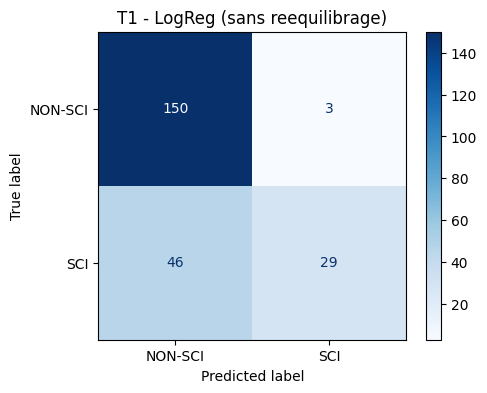

In [ ]:
print(classification_report(y_test, y_pred, target_names=['NON-SCI', 'SCI']))


fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['NON-SCI', 'SCI']).plot(ax=ax, cmap='Blues')
ax.set_title('T1 - LogReg (sans reequilibrage)')
plt.show()

### Tf-idf avec le nettoyage et les ajouts

In [ ]:
df_clean = main_pre_treatment_v2(df_original,
                                  use_numeric_features=True,
                                  use_special_tokens=True,
                                  filter_non_latin=True,
                                  keep_negations=True,
                                  use_lemmatization=True)

# Donnees pour T1
X_t1 = df_clean['text_lemmatized']
y_t1 = df_clean['science_related'].values

print(f'Total tweets : {len(X_t1)}')
print(f'Distribution y_t1 : NON-SCI={np.sum(y_t1==0)}, SCI={np.sum(y_t1==1)} (ratio = {np.sum(y_t1==1)/len(y_t1):.1%})')

# Split stratifie 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X_t1, y_t1, test_size=0.2, stratify=y_t1, random_state=RANDOM_STATE
)
print(f'\nTrain : {len(X_train)} tweets')
print(f'Test  : {len(X_test)} tweets')
print(f'Distribution y_train : NON-SCI={np.sum(y_train==0)}, SCI={np.sum(y_train==1)} (ratio = {np.sum(y_train==1)/len(y_train):.1%})')

# Pipeline : TF-IDF -> [sampler='passthrough'] -> LogReg
# Pour cette premiere passe : class_weight=None (pas de correction du desequilibre).
# Mettre class_weight='balanced' pour voir l'effet sur le recall de la classe minoritaire.
pipe = make_pipeline(class_weight='balanced')

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

# Sanity check : shape de la matrice TF-IDF apres fit
print(f'\nShape TF-IDF train : {pipe.named_steps["tfidf"].transform(X_train).shape}')
print(f'Shape TF-IDF test  : {pipe.named_steps["tfidf"].transform(X_test).shape}')

Total tweets : 1140
Distribution y_t1 : NON-SCI=765, SCI=375 (ratio = 32.9%)

Train : 912 tweets
Test  : 228 tweets
Distribution y_train : NON-SCI=612, SCI=300 (ratio = 32.9%)

Shape TF-IDF train : (912, 1714)
Shape TF-IDF test  : (228, 1714)


=== Classification report ===
              precision    recall  f1-score   support

     NON-SCI       0.89      0.88      0.88       153
         SCI       0.75      0.77      0.76        75

    accuracy                           0.84       228
   macro avg       0.82      0.82      0.82       228
weighted avg       0.84      0.84      0.84       228



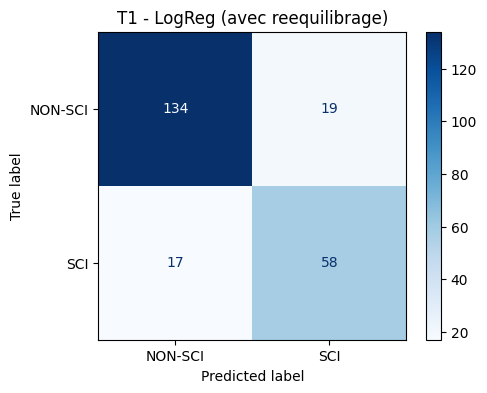

In [ ]:
# Classification report
print('=== Classification report ===')
print(classification_report(y_test, y_pred, target_names=['NON-SCI', 'SCI']))

# Matrice de confusion
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['NON-SCI', 'SCI']).plot(ax=ax, cmap='Blues')
ax.set_title('T1 - LogReg (avec reequilibrage)')
plt.show()

##Préparation des données finales (les 3 tâches)
Démarche :
 Avant de lancer la modélisation, nous préparons les trois jeux de données correspondant aux trois tâches de la consigne. Nous partons de df_original avec le prétraitement complet (v2), puis nous filtrons les tweets SCI pour les tâches 2 et 3. Le point délicat est la dérivation des labels pour T2 et T3 : le dataset est multi-label (un tweet peut être à la fois CLAIM et REF), donc nous appliquons une convention de priorité CLAIM > REF > CONTEXT pour T3, et nous regroupons CLAIM+REF en une seule classe pour T2. Nous vérifions systématiquement la distribution pour anticiper les problèmes de déséquilibre.

> Ajouter une citation



In [ ]:

df_clean = main_pre_treatment_v2(
    df_original,
    use_numeric_features=True,
    use_special_tokens=True,
    filter_non_latin=True,
    keep_negations=True,
    use_lemmatization=True
)

NUMERIC_FEATURES = ['nb_links', 'nb_arobases', 'nb_hashtag',
                    'nb_emoji', 'has_question', 'has_exclamation', 'nb_uppercase']


X_text_t1 = df_clean['text_lemmatized'].values
y_t1       = df_clean['science_related'].values

print(f"T1 — Total : {len(y_t1)} | NON-SCI : {(y_t1==0).sum()} | SCI : {(y_t1==1).sum()}")


df_sci = df_clean[df_clean['science_related'] == 1].copy().reset_index(drop=True)
print(f"\nTweets SCI retenus pour T2/T3 : {len(df_sci)}")
print(f"  CLAIM   : {df_sci['scientific_claim'].sum()}")
print(f"  REF     : {df_sci['scientific_reference'].sum()}")
print(f"  CONTEXT : {df_sci['scientific_context'].sum()}")


df_sci['label_t2'] = ((df_sci['scientific_claim'] == 1) |
                      (df_sci['scientific_reference'] == 1)).astype(int)

X_text_t2 = df_sci['text_lemmatized'].values
y_t2       = df_sci['label_t2'].values
print(f"\nT2 — CLAIM/REF : {(y_t2==1).sum()} | CONTEXT : {(y_t2==0).sum()}")

def assign_t3_label(row):
    if row['scientific_claim'] == 1:       return 0
    elif row['scientific_reference'] == 1: return 1
    else:                                  return 2

df_sci['label_t3'] = df_sci.apply(assign_t3_label, axis=1)

X_text_t3 = df_sci['text_lemmatized'].values
y_t3       = df_sci['label_t3'].values
print(f"\nT3 — CLAIM : {(y_t3==0).sum()} | REF : {(y_t3==1).sum()} | CONTEXT : {(y_t3==2).sum()}")

T1 — Total : 1140 | NON-SCI : 765 | SCI : 375

Tweets SCI retenus pour T2/T3 : 375
  CLAIM   : 263.0
  REF     : 203.0
  CONTEXT : 251.0

T2 — CLAIM/REF : 342 | CONTEXT : 33

T3 — CLAIM : 263 | REF : 79 | CONTEXT : 33


## Fonction de cross-validation
Démarche :
Nous définissons une fonction générique cross_val_evaluate qui prend en entrée un jeu de données (texte + labels) et un nom de tâche, et renvoie les métriques agrégées sur 5 folds. L'aspect critique est l'ordre des opérations dans chaque fold : (1) split, (2) TF-IDF fitté sur le train uniquement, (3) SMOTE appliqué sur le train uniquement, (4) entraînement, (5) évaluation sur le test. Inverser cet ordre provoquerait un data leakage qui gonflerait artificiellement les performances. Nous utilisons clone de sklearn pour réinitialiser proprement chaque modèle entre les folds.

In [ ]:
def cross_val_evaluate(X_text, y, task_name, average='binary'):
    """
    Cross-validation stratifiée 5 folds sans data leakage :
      - TF-IDF et SMOTE sont appliqués uniquement sur les données d'entraînement
      - Évaluation sur le fold test vierge
    """

    models = {
        'ComplementNB': ComplementNB(),

        'LogReg': LogisticRegression(
            max_iter=2000,
            class_weight='balanced',
            random_state=RANDOM_STATE
        ),

        'LinearSVC': LinearSVC(
            class_weight='balanced',
            random_state=RANDOM_STATE,
            max_iter=5000
        ),

        'RandomForest': RandomForestClassifier(
            n_estimators=300,
            class_weight='balanced',
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),

        'KNN': KNeighborsClassifier(
            n_neighbors=7
        ),

        # Modèles réseau de neurones / deep learning léger
        'MLP_1couche': MLPClassifier(
            hidden_layer_sizes=(64,),
            activation='relu',
            solver='adam',
            alpha=1e-4,
            learning_rate_init=1e-3,
            max_iter=400,
            early_stopping=True,
            random_state=RANDOM_STATE
        ),

        'MLP_2couches': MLPClassifier(
            hidden_layer_sizes=(128, 32),
            activation='relu',
            solver='adam',
            alpha=1e-4,
            learning_rate_init=1e-3,
            max_iter=400,
            early_stopping=True,
            random_state=RANDOM_STATE
        ),
    }

    raw_results = []

    for fold_idx, (train_idx, test_idx) in enumerate(CV.split(X_text, y)):
        X_tr_raw, X_te_raw = X_text[train_idx], X_text[test_idx]
        y_tr, y_te = y[train_idx], y[test_idx]

        tfidf_fold = TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            sublinear_tf=True,
            min_df=2,
            max_df=0.95
        )

        X_tr = tfidf_fold.fit_transform(X_tr_raw)
        X_te = tfidf_fold.transform(X_te_raw)

        smote = SMOTE(random_state=RANDOM_STATE)
        X_tr_b, y_tr_b = smote.fit_resample(X_tr, y_tr)

        for name, model in models.items():
            m = clone(model)
            m.fit(X_tr_b, y_tr_b)
            y_pred = m.predict(X_te)

            raw_results.append({
                'task': task_name,
                'model': name,
                'fold': fold_idx + 1,
                'accuracy': accuracy_score(y_te, y_pred),
                'precision': precision_score(y_te, y_pred, average=average, zero_division=0),
                'recall': recall_score(y_te, y_pred, average=average, zero_division=0),
                'f1': f1_score(y_te, y_pred, average=average, zero_division=0),
                'macro_f1': f1_score(y_te, y_pred, average='macro', zero_division=0),
            })

    raw = pd.DataFrame(raw_results)

    summary = (
        raw.groupby('model')[['accuracy', 'precision', 'recall', 'f1', 'macro_f1']]
        .agg(['mean', 'std'])
        .round(3)
    )

    summary.columns = ['_'.join(c) for c in summary.columns]
    summary.insert(0, 'task', task_name)

    return summary, raw

## Lancement de la cross-validation sur les 3 tâches
Démarche :
Nous appelons la fonction pour chacune des trois tâches. Le paramètre average change entre T1/T2 (binaire → 'binary') et T3 (3 classes → 'macro'). Le macro-F1 est le plus honnête en cas de déséquilibre car il donne le même poids à chaque classe indépendamment de sa taille.

In [ ]:

print(" Tâche 1 : SCI vs NON-SCI")

summary_t1, raw_t1 = cross_val_evaluate(
    X_text_t1, y_t1,
    task_name='T1_SCI_vs_NONSCI',
    average='binary'
)
print(summary_t1[['task','macro_f1_mean','macro_f1_std','accuracy_mean','precision_mean','recall_mean']])

print("\n")
print(" Tâche 2 : {CLAIM, REF} vs {CONTEXT}")

summary_t2, raw_t2 = cross_val_evaluate(
    X_text_t2, y_t2,
    task_name='T2_CLAIMREF_vs_CONTEXT',
    average='binary'
)
print(summary_t2[['task','macro_f1_mean','macro_f1_std','accuracy_mean','precision_mean','recall_mean']])

print("\n")
print(" Tâche 3 : CLAIM vs REF vs CONTEXT")

summary_t3, raw_t3 = cross_val_evaluate(
    X_text_t3, y_t3,
    task_name='T3_CLAIM_REF_CONTEXT',
    average='macro'
)
print(summary_t3[['task','macro_f1_mean','macro_f1_std','accuracy_mean','precision_mean','recall_mean']])

 Tâche 1 : SCI vs NON-SCI
                          task  macro_f1_mean  macro_f1_std  accuracy_mean  \
model                                                                        
ComplementNB  T1_SCI_vs_NONSCI          0.765         0.026          0.782   
KNN           T1_SCI_vs_NONSCI          0.334         0.016          0.382   
LinearSVC     T1_SCI_vs_NONSCI          0.785         0.026          0.809   
LogReg        T1_SCI_vs_NONSCI          0.794         0.020          0.813   
MLP_1couche   T1_SCI_vs_NONSCI          0.774         0.030          0.799   
MLP_2couches  T1_SCI_vs_NONSCI          0.753         0.042          0.788   
RandomForest  T1_SCI_vs_NONSCI          0.778         0.016          0.814   

              precision_mean  recall_mean  
model                                      
ComplementNB           0.641        0.771  
KNN                    0.346        0.989  
LinearSVC              0.705        0.728  
LogReg                 0.695        0.771  
MLP_1co

## Optimisation des hyperparamètres par GridSearchCV du meilleur modèle par tâche

Démarche : La cross-validation du Bloc C nous a donné le meilleur modèle pour chaque tâche. Nous appliquons dès à présent un GridSearchCV uniquement sur ce modèle tout en conservant la même logique sans data leakage : le TF-IDF est intégré dans le pipeline sklearn, ce qui garantit qu'il est refitté sur chaque fold train du grid search. Le SMOTE pose un problème ici : GridSearchCV de sklearn ne supporte pas nativement les samplers d'imbalanced-learn. On utilise donc ImbPipeline (déjà importé) qui gère correctement SMOTE à l'intérieur de chaque fold. Le scoring est le macro F1 qui cohérent avec ce que nous avons utilisé en cross-val.

In [ ]:
from sklearn.model_selection import GridSearchCV

def make_grid_pipeline(model_name):
    """
    Construit un ImbPipeline : TF-IDF -> SMOTE -> classifieur.
    Retourne aussi la grille d'hyperparamètres associée.
    Les préfixes 'tfidf__', 'smote__', 'clf__' sont imposés par le pipeline.
    """
    models_and_grids = {
        'LogReg': (
            LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
            {
                'clf__C':           [0.01, 0.1, 1, 10, 100],
                'clf__class_weight': [None, 'balanced'],
                'clf__solver':      ['lbfgs', 'liblinear'],
            }
        ),
        'LinearSVC': (
            LinearSVC(max_iter=5000, random_state=RANDOM_STATE),
            {
                'clf__C':            [0.01, 0.1, 1, 10, 100],
                'clf__class_weight': [None, 'balanced'],
            }
        ),
        'RandomForest': (
            RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
            {
                'clf__n_estimators':  [100, 300, 500],
                'clf__max_depth':     [None, 10, 30],
                'clf__class_weight':  [None, 'balanced'],
            }
        ),
        'ComplementNB': (
            ComplementNB(),
            {
                'clf__alpha': [0.01, 0.1, 0.5, 1.0, 2.0],
            }
        ),
        'KNN': (
            KNeighborsClassifier(),
            {
                'clf__n_neighbors': [3, 5, 7, 11, 15],
                'clf__metric':      ['euclidean', 'cosine'],
            }
        ),
        'MLP_1couche': (
            MLPClassifier(
                hidden_layer_sizes=(64,),
                activation='relu',
                solver='adam',
                max_iter=400,
                early_stopping=True,
                random_state=RANDOM_STATE
            ),
            {
                'clf__alpha': [1e-4, 1e-3],
                'clf__learning_rate_init': [1e-3],
            }
        ),

        'MLP_2couches': (
            MLPClassifier(
                hidden_layer_sizes=(128, 32),
                activation='relu',
                solver='adam',
                max_iter=400,
                early_stopping=True,
                random_state=RANDOM_STATE
            ),
            {
                'clf__alpha': [1e-4, 1e-3],
                'clf__learning_rate_init': [1e-3],
            }
        ),
    }

    clf, param_grid = models_and_grids[model_name]

    pipeline = ImbPipeline([
        ('tfidf',  TfidfVectorizer(max_features=5000, ngram_range=(1, 2),
                                   sublinear_tf=True, min_df=2, max_df=0.95)),
        ('smote',  SMOTE(random_state=RANDOM_STATE)),
        ('clf',    clf),
    ])

    return pipeline, param_grid


def run_grid_search(X_text, y, model_name, task_name, average='binary'):
    """
    Lance le GridSearchCV sur le modèle donné pour une tâche donnée.
    Retourne le meilleur estimateur et un résumé des résultats.
    """
    pipeline, param_grid = make_grid_pipeline(model_name)

    grid = GridSearchCV(
        pipeline,
        param_grid,
        scoring=f'f1_macro',
        cv=CV,
        n_jobs=-1,
        verbose=1,
        refit=True
    )


    X_tr, X_te, y_tr, y_te = train_test_split(
        X_text, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
    )


    print(f"GridSearch — {task_name} — {model_name}")

    grid.fit(X_tr, y_tr)

    print(f"Meilleurs paramètres : {grid.best_params_}")
    print(f"Meilleur score CV (macro F1) : {grid.best_score_:.4f}")


    y_pred = grid.predict(X_te)
    print(f"\n Évaluation sur le test set ")
    print(classification_report(y_te, y_pred, zero_division=0))

    return grid, X_te, y_te

In [ ]:
best_t1 = summary_t1['macro_f1_mean'].idxmax()
best_t2 = summary_t2['macro_f1_mean'].idxmax()
best_t3 = summary_t3['macro_f1_mean'].idxmax()

print(f"Modèle retenu T1 : {best_t1}")
print(f"Modèle retenu T2 : {best_t2}")
print(f"Modèle retenu T3 : {best_t3}")


grid_t1, X_te_t1, y_te_t1 = run_grid_search(
    X_text_t1, y_t1, best_t1,
    task_name='T1_SCI_vs_NONSCI',
    average='binary'
)

grid_t2, X_te_t2, y_te_t2 = run_grid_search(
    X_text_t2, y_t2, best_t2,
    task_name='T2_CLAIMREF_vs_CONTEXT',
    average='binary'
)

grid_t3, X_te_t3, y_te_t3 = run_grid_search(
    X_text_t3, y_t3, best_t3,
    task_name='T3_CLAIM_REF_CONTEXT',
    average='macro'
)

Modèle retenu T1 : LogReg
Modèle retenu T2 : MLP_2couches
Modèle retenu T3 : LogReg
GridSearch — T1_SCI_vs_NONSCI — LogReg
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Meilleurs paramètres : {'clf__C': 1, 'clf__class_weight': None, 'clf__solver': 'liblinear'}
Meilleur score CV (macro F1) : 0.7806

 Évaluation sur le test set 
              precision    recall  f1-score   support

           0       0.86      0.88      0.87       153
           1       0.74      0.72      0.73        75

    accuracy                           0.82       228
   macro avg       0.80      0.80      0.80       228
weighted avg       0.82      0.82      0.82       228

GridSearch — T2_CLAIMREF_vs_CONTEXT — MLP_2couches
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Meilleurs paramètres : {'clf__alpha': 0.0001, 'clf__learning_rate_init': 0.001}
Meilleur score CV (macro F1) : 0.5189

 Évaluation sur le test set 
              precision    recall  f1-score   support

           0  

##Visualisation comparative
Démarche :
Nous produisons deux types de visualisations. D'abord, un graphique en barres horizontales avec barres d'erreur (écart-type inter-folds) pour comparer les modèles sur chaque tâches. Ensuite un tableau fusionné propre, que nous  pourrons intégrer directement dans le rapport.

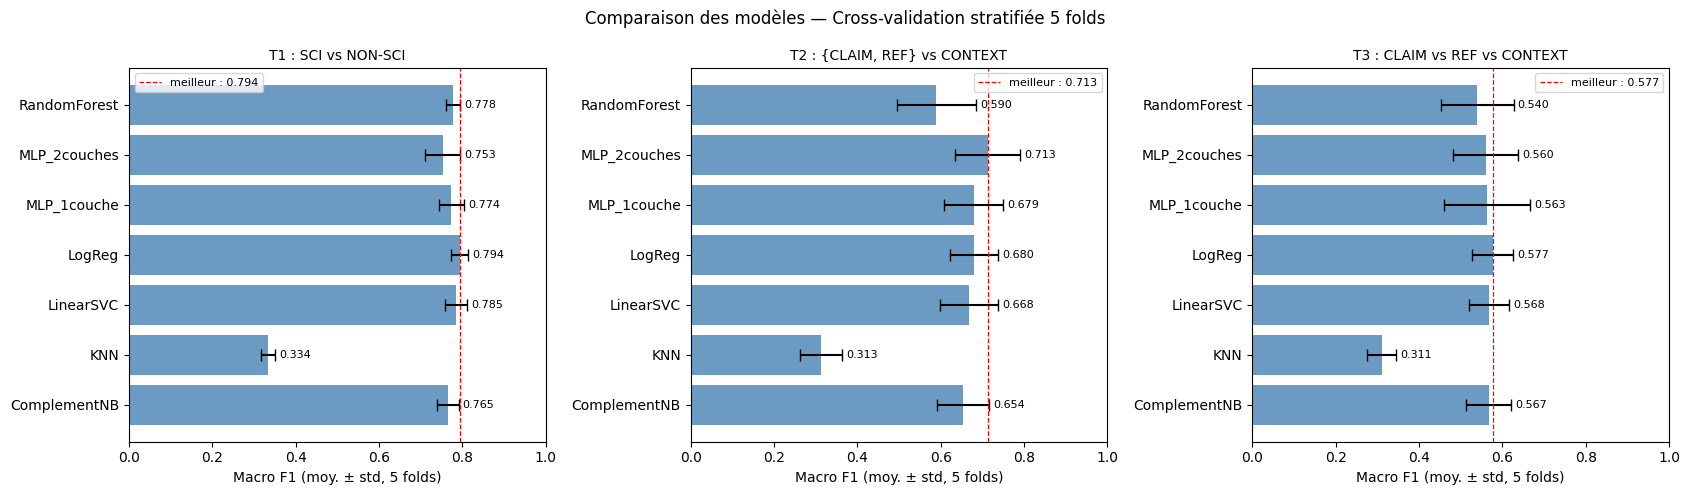


 Tableau comparatif global 
                                task  accuracy_mean  accuracy_std  precision_mean  recall_mean  macro_f1_mean  macro_f1_std
model                                                                                                                      
ComplementNB        T1_SCI_vs_NONSCI          0.782         0.023           0.641        0.771          0.765         0.026
KNN                 T1_SCI_vs_NONSCI          0.382         0.010           0.346        0.989          0.334         0.016
LinearSVC           T1_SCI_vs_NONSCI          0.809         0.026           0.705        0.728          0.785         0.026
LogReg              T1_SCI_vs_NONSCI          0.813         0.017           0.695        0.771          0.794         0.020
MLP_1couche         T1_SCI_vs_NONSCI          0.799         0.024           0.687        0.717          0.774         0.030
MLP_2couches        T1_SCI_vs_NONSCI          0.788         0.028           0.695        0.640         

In [ ]:
import os

figures_path = my_local_drive + '/figures'
os.makedirs(figures_path, exist_ok=True)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

tasks_viz = [
    ('T1 : SCI vs NON-SCI',          summary_t1),
    ('T2 : {CLAIM, REF} vs CONTEXT', summary_t2),
    ('T3 : CLAIM vs REF vs CONTEXT', summary_t3),
]

for ax, (title, summary) in zip(axes, tasks_viz):
    means = summary['macro_f1_mean']
    stds  = summary['macro_f1_std']
    mdls  = summary.index

    ax.barh(
        mdls,
        means,
        xerr=stds,
        capsize=4,
        color='steelblue',
        alpha=0.8,
        ecolor='black'
    )

    ax.axvline(
        means.max(),
        color='red',
        linestyle='--',
        linewidth=0.9,
        label=f'meilleur : {means.max():.3f}'
    )

    ax.set_xlim(0, 1)
    ax.set_xlabel('Macro F1 (moy. ± std, 5 folds)')
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)

    for i, (m, s) in enumerate(zip(means, stds)):
        ax.text(
            min(m + s + 0.01, 0.97),
            i,
            f'{m:.3f}',
            va='center',
            fontsize=8
        )

plt.suptitle('Comparaison des modèles — Cross-validation stratifiée 5 folds', fontsize=12)
plt.tight_layout()

plt.savefig(
    figures_path + '/comparaison_modeles_cross_validation.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

all_summaries = pd.concat([summary_t1, summary_t2, summary_t3])
cols_rapport = [
    'task',
    'accuracy_mean',
    'accuracy_std',
    'precision_mean',
    'recall_mean',
    'macro_f1_mean',
    'macro_f1_std'
]

print("\n Tableau comparatif global ")
print(all_summaries[cols_rapport].to_string())

print("\nFigure sauvegardée dans :")
print(figures_path + '/comparaison_modeles_cross_validation.png')

##Matrices de confusion (meilleur modèle par tâche, sur un fold)
Démarche :  Nous rejouons le meilleur modèle identifié par la cross-val sur un split 80/20 dédié (stratifié) afin d'obtenir une matrice lisible. Ensuite, nous affichons les 3 tâches côte à côte.

Meilleur modèle T1 : LogReg
Meilleur modèle T2 : MLP_2couches
Meilleur modèle T3 : LogReg

 T1 — LogReg 
              precision    recall  f1-score   support

     NON-SCI       0.86      0.88      0.87       153
         SCI       0.74      0.72      0.73        75

    accuracy                           0.82       228
   macro avg       0.80      0.80      0.80       228
weighted avg       0.82      0.82      0.82       228


 T2 — MLP_2couches 
              precision    recall  f1-score   support

     CONTEXT       0.38      0.71      0.50         7
   CLAIM/REF       0.97      0.88      0.92        68

    accuracy                           0.87        75
   macro avg       0.68      0.80      0.71        75
weighted avg       0.91      0.87      0.88        75


 T3 — LogReg 
              precision    recall  f1-score   support

       CLAIM       0.86      0.83      0.84        52
         REF       0.40      0.38      0.39        16
     CONTEXT       0.50      0.71      0.5

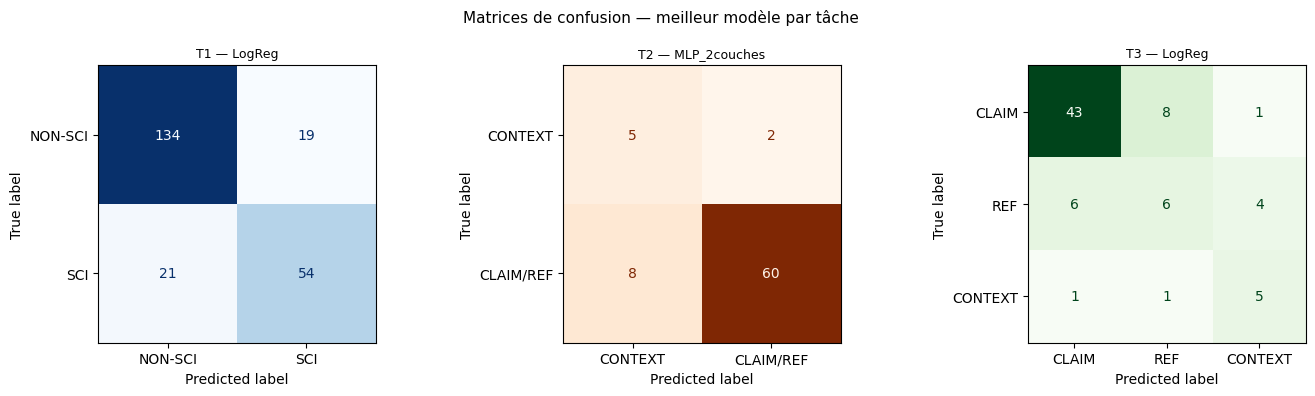


Figure sauvegardée dans :
/content/drive/MyDrive/Projet ML1 Master ICo/figures/matrices_confusion_meilleurs_modeles.png


In [ ]:
import os

figures_path = my_local_drive + '/figures'
os.makedirs(figures_path, exist_ok=True)

def confusion_best_model(X_text, y, best_model_name, task_name,
                          label_names, average='binary'):
    # Entraîne le meilleur modèle sur 80% et affiche la matrice de confusion.

    models_ref = {
        'ComplementNB': ComplementNB(),

        'LogReg': LogisticRegression(
            max_iter=2000,
            class_weight='balanced',
            random_state=RANDOM_STATE
        ),

        'LinearSVC': LinearSVC(
            class_weight='balanced',
            random_state=RANDOM_STATE,
            max_iter=5000
        ),

        'RandomForest': RandomForestClassifier(
            n_estimators=300,
            class_weight='balanced',
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),

        'KNN': KNeighborsClassifier(
            n_neighbors=7
        ),

        'MLP_1couche': MLPClassifier(
            hidden_layer_sizes=(64,),
            activation='relu',
            solver='adam',
            alpha=1e-4,
            learning_rate_init=1e-3,
            max_iter=400,
            early_stopping=True,
            random_state=RANDOM_STATE
        ),

        'MLP_2couches': MLPClassifier(
            hidden_layer_sizes=(128, 32),
            activation='relu',
            solver='adam',
            alpha=1e-4,
            learning_rate_init=1e-3,
            max_iter=400,
            early_stopping=True,
            random_state=RANDOM_STATE
        ),
    }

    model = models_ref[best_model_name]

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_text,
        y,
        test_size=0.2,
        stratify=y,
        random_state=RANDOM_STATE
    )

    tfidf_cm = TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        sublinear_tf=True,
        min_df=2,
        max_df=0.95
    )

    X_tr_v = tfidf_cm.fit_transform(X_tr)
    X_te_v = tfidf_cm.transform(X_te)

    smote = SMOTE(random_state=RANDOM_STATE)
    X_tr_b, y_tr_b = smote.fit_resample(X_tr_v, y_tr)

    model.fit(X_tr_b, y_tr_b)
    y_pred = model.predict(X_te_v)

    print(f"\n {task_name} — {best_model_name} ")
    print(classification_report(y_te, y_pred, target_names=label_names, zero_division=0))

    return confusion_matrix(y_te, y_pred), y_te, y_pred, label_names, task_name, best_model_name


best_t1 = summary_t1['macro_f1_mean'].idxmax()
best_t2 = summary_t2['macro_f1_mean'].idxmax()
best_t3 = summary_t3['macro_f1_mean'].idxmax()

print(f"Meilleur modèle T1 : {best_t1}")
print(f"Meilleur modèle T2 : {best_t2}")
print(f"Meilleur modèle T3 : {best_t3}")

cm1, *args1 = confusion_best_model(
    X_text_t1,
    y_t1,
    best_t1,
    'T1',
    ['NON-SCI', 'SCI']
)

cm2, *args2 = confusion_best_model(
    X_text_t2,
    y_t2,
    best_t2,
    'T2',
    ['CONTEXT', 'CLAIM/REF']
)

cm3, *args3 = confusion_best_model(
    X_text_t3,
    y_t3,
    best_t3,
    'T3',
    ['CLAIM', 'REF', 'CONTEXT']
)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, cm, args, cmap in zip(
    axes,
    [cm1, cm2, cm3],
    [args1, args2, args3],
    ['Blues', 'Oranges', 'Greens']
):
    _, _, label_names, task_name, model_name = args

    ConfusionMatrixDisplay(
        cm,
        display_labels=label_names
    ).plot(
        ax=ax,
        cmap=cmap,
        colorbar=False
    )

    ax.set_title(f"{task_name} — {model_name}", fontsize=9)

plt.suptitle('Matrices de confusion — meilleur modèle par tâche', fontsize=11)
plt.tight_layout()

plt.savefig(
    figures_path + '/matrices_confusion_meilleurs_modeles.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("\nFigure sauvegardée dans :")
print(figures_path + '/matrices_confusion_meilleurs_modeles.png')

##Features discriminantes
Il est également demandé d'identifier les features les plus discriminantes par classe. Pour ce faire, nous exploitons les coefficients des modèles linéaires (LogReg, LinearSVC) : chaque feature (mot ou bigramme TF-IDF) possède un coefficient par classe et les coefficients les plus élevés correspondent aux mots les plus caractéristiques. On refit le modèle sur 100% des données pour avoir les coefficients finaux les plus représentatifs, en enfin nous affichons le top 15 par classe.

In [ ]:
def top_features(model, tfidf_vectorizer, class_names, top_n=15):
    # Affiche les features les plus discriminantes pour les modèles linéaires.
    if not hasattr(model, 'coef_'):
        print(f"  {type(model).__name__} ne supporte pas l'extraction de features (pas de coef_).")
        return

    feature_names = np.array(tfidf_vectorizer.get_feature_names_out())
    coefs = model.coef_
    if coefs.shape[0] == 1:
        coefs = np.vstack([-coefs[0], coefs[0]])

    for i, cls in enumerate(class_names):
        top_idx = np.argsort(coefs[i])[-top_n:][::-1]
        print(f"  Top {top_n} mots discriminants pour [{cls}] :")
        for idx in top_idx:
            print(f"    {feature_names[idx]:<30}  coef = {coefs[i][idx]:.4f}")
        print()


def fit_for_features(X_text, y, model):
    # Fit TF-IDF + modèle sur 100% des données pour l'extraction de features.
    tfidf_full = TfidfVectorizer(max_features=5000, ngram_range=(1,2),
                                  sublinear_tf=True, min_df=2, max_df=0.95)
    X_full = tfidf_full.fit_transform(X_text)
    smote  = SMOTE(random_state=RANDOM_STATE)
    X_b, y_b = smote.fit_resample(X_full, y)
    model.fit(X_b, y_b)
    return model, tfidf_full



print("BONUS — T1 : Features discriminantes (LogReg)")

logreg_t1, tfidf_feat_t1 = fit_for_features(
    X_text_t1, y_t1,
    LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE)
)
top_features(logreg_t1, tfidf_feat_t1, ['NON-SCI', 'SCI'])


print("BONUS — T2 : Features discriminantes (LinearSVC)")

svc_t2, tfidf_feat_t2 = fit_for_features(
    X_text_t2, y_t2,
    LinearSVC(class_weight='balanced', random_state=RANDOM_STATE, max_iter=5000)
)
top_features(svc_t2, tfidf_feat_t2, ['CONTEXT', 'CLAIM/REF'])


print("BONUS — T3 : Features discriminantes (LinearSVC)")

svc_t3, tfidf_feat_t3 = fit_for_features(
    X_text_t3, y_t3,
    LinearSVC(class_weight='balanced', random_state=RANDOM_STATE, max_iter=5000)
)
top_features(svc_t3, tfidf_feat_t3, ['CLAIM', 'REF', 'CONTEXT'])

BONUS — T1 : Features discriminantes (LogReg)
  Top 15 mots discriminants pour [NON-SCI] :
    stop                            coef = 4.5844
    support                         coef = 3.8342
    report                          coef = 2.1407
    need                            coef = 1.5114
    treat                           coef = 1.3761
    promote                         coef = 1.2952
    usertoken                       coef = 1.2847
    get                             coef = 1.1865
    trump                           coef = 1.1150
    please                          coef = 1.0892
    news                            coef = 1.0233
    engineer                        coef = 0.9605
    numtoken                        coef = 0.9335
    thing                           coef = 0.9286
    lower                           coef = 0.8928

  Top 15 mots discriminants pour [SCI] :
    urltoken                        coef = 3.5394
    health                          coef = 2.6293
    research     

##Export des résultats

In [ ]:
import json

def serialize(obj):
    # Convertit les types numpy/pandas en types Python natifs pour JSON.
    if isinstance(obj, (np.integer,)):  return int(obj)
    if isinstance(obj, (np.floating,)): return float(obj)
    if isinstance(obj, np.ndarray):     return obj.tolist()
    return str(obj)

resultats = {
    "cross_validation": {
        "T1": json.loads(summary_t1.reset_index().to_json(orient='records')),
        "T2": json.loads(summary_t2.reset_index().to_json(orient='records')),
        "T3": json.loads(summary_t3.reset_index().to_json(orient='records')),
    },
    "grid_search": {
        "T1": {"best_params": grid_t1.best_params_, "best_cv_score": grid_t1.best_score_,
               "test_f1_macro": float(f1_score(y_te_t1, grid_t1.predict(X_te_t1), average='macro', zero_division=0)),
               "classification_report": classification_report(y_te_t1, grid_t1.predict(X_te_t1), output_dict=True, zero_division=0)},
        "T2": {"best_params": grid_t2.best_params_, "best_cv_score": grid_t2.best_score_,
               "test_f1_macro": float(f1_score(y_te_t2, grid_t2.predict(X_te_t2), average='macro', zero_division=0)),
               "classification_report": classification_report(y_te_t2, grid_t2.predict(X_te_t2), output_dict=True, zero_division=0)},
        "T3": {"best_params": grid_t3.best_params_, "best_cv_score": grid_t3.best_score_,
               "test_f1_macro": float(f1_score(y_te_t3, grid_t3.predict(X_te_t3), average='macro', zero_division=0)),
               "classification_report": classification_report(y_te_t3, grid_t3.predict(X_te_t3), output_dict=True, zero_division=0)},
    },
    "distributions": {
        "T1": {"NON-SCI": int((y_t1==0).sum()), "SCI": int((y_t1==1).sum())},
        "T2": {"CONTEXT": int((y_t2==0).sum()), "CLAIM_REF": int((y_t2==1).sum())},
        "T3": {"CLAIM": int((y_t3==0).sum()), "REF": int((y_t3==1).sum()), "CONTEXT": int((y_t3==2).sum())},
    }
}


output_path = my_local_drive + '/resultats_ml.json'
with open(output_path, 'w') as f:
    json.dump(resultats, f, indent=2, default=serialize)

print(f"Résultats exportés : {output_path}")

Résultats exportés : /content/drive/MyDrive/Projet ML1 Master ICo/resultats_ml.json


# Conclusion

En conclusion, les résultats obtenus montrent que les modèles de machine learning permettent de classer efficacement les tweets selon leur contenu scientifique.

Les modèles linéaires offrent les meilleures performances.
Néanmoins, la présence d’un déséquilibre des classes ainsi que la complexité des tâches multi-classes limitent les performances, notamment pour la distinction entre les catégories claim, reference et context.

Des améliorations pourraient être envisagés à travers l’utilisation de modèles plus avancés et un meilleur équilibrage des données.

In [ ]:
# Install TeX Live packages for PDF conversion
!apt-get install texlive-xetex texlive-fonts-recommended texlive-plain-generic -y

# Retry PDF conversion
import os
notebook_path = '/content/drive/MyDrive/Projet ML1 Master ICo/Scitweets.ipynb'

if os.path.exists(notebook_path):
    !jupyter nbconvert "{notebook_path}" --to pdf
    print(f"Successfully converted '{notebook_path}' to PDF.")
else:
    print(f"Error: Notebook file '{notebook_path}' not found. Please ensure the notebook is saved and the path is correct.")

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
texlive-fonts-recommended is already the newest version (2021.20220204-1).
texlive-plain-generic is already the newest version (2021.20220204-1).
texlive-xetex is already the newest version (2021.20220204-1).
0 upgraded, 0 newly installed, 0 to remove and 3 not upgraded.
[NbConvertApp] Converting notebook /content/drive/MyDrive/Projet ML1 Master ICo/Scitweets.ipynb to pdf
[NbConvertApp] Support files will be in Scitweets_files/
[NbConvertApp] Making directory ./Scitweets_files
[NbConvertApp] Writing 208368 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 212927 bytes to /content/drive/MyDrive/Projet ML1